# Phenix - Reconnaissance supervisée d'injections SQL connues

TF-IDF de séquences de 2 à 5 caractères et régression logistique : le vocabulaire et les poids sont appris sur des exemples normaux et SQL étiquetés. Le score n'est pas une probabilité de risque opérationnel calibrée. Les étiquettes viennent des scénarios, pas du SIEM.

Le seuil est choisi sur la calibration étiquetée pour maximiser le rappel sous une contrainte empirique de 1 % de faux positifs. Validation et test ne servent ni à entraîner le modèle ni à choisir ce seuil.

Placer ce notebook dans backend/ML/notebooks, choisir un noyau avec pandas, numpy et matplotlib puis Exécuter tout. EXPERIMENT vaut local-sql-v1. Les sorties enregistrées illustrent l'essai synthétique calculé ici ; relancer pour analyser votre entraînement. Aucun joblib n'est chargé par ce notebook et aucune action système n'est effectuée.

Ce nouveau protocole supervisé utilise un autre jeu de données : il n'est pas directement comparable au premier essai WAF entraîné seulement sur le trafic normal.


In [1]:
from pathlib import Path
import json
from urllib.parse import unquote_plus
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EXPERIMENT = "local-sql-v1"
roots = [candidate for parent in [Path.cwd(), *Path.cwd().parents]
         for candidate in [parent, parent / "backend" / "ML"]
         if (candidate / "experiments" / EXPERIMENT / "metrics.json").is_file()]
if not roots:
    raise FileNotFoundError("Vérifier EXPERIMENT ; placer le notebook dans backend/ML/notebooks")
EXP_DIR = roots[0] / "experiments" / EXPERIMENT
report = json.loads((EXP_DIR / "metrics.json").read_text(encoding="utf-8"))
assert report["metadata"]["feature_schema"] == "waf-sql-char-supervised-v1"
assert "test" not in report["splits"], "Ce notebook est réservé à la validation exploratoire."
threshold = report["metadata"]["threshold"]
print("Expérience :", EXPERIMENT)
print("Seuil choisi sur la calibration étiquetée :", round(threshold, 6))
print("Modèle :", report["metadata"]["model"])
print("Taille du vocabulaire appris :", report["metadata"]["vocabulary_size"])
print("Séquences de caractères :", report["metadata"]["ngram_range"])


Expérience : local-sql-v1
Seuil choisi sur la calibration étiquetée : 0.061988
Modèle : TFIDF_char_LogisticRegression
Taille du vocabulaire appris : 12135
Séquences de caractères : [2, 5]


## 1. Résultats par requête

VP : tentative annotée détectée ; FN : tentative manquée ; FP : requête normale signalée ; VN : requête normale non signalée. Les tentatives ne sont pas nécessairement des injections réussies.

La précision et le rappel ne sont pas définis quand leur dénominateur est nul (NaN dans le tableau). Les résultats d'apprentissage et de calibration ne sont pas des évaluations indépendantes.


In [2]:
predictions = {}
rows = []
for name in ["train", "calibration", "validation"]:
    df = pd.read_csv(EXP_DIR / f"{name}_predictions.csv", keep_default_na=False, dtype={"loki_timestamp_ns": str})
    df["observed_at"] = pd.to_datetime(df.observed_at, utc=True)
    assert df.loki_timestamp_ns.is_unique
    y = df.is_attack.eq(1)
    p = df.predicted_sql.eq(1)
    assert np.array_equal(p.to_numpy(), (df.sql_score > threshold).to_numpy())
    counts = {"true_positive": int((y & p).sum()), "false_positive": int((~y & p).sum()),
              "false_negative": int((y & ~p).sum()), "true_negative": int((~y & ~p).sum())}
    for key, value in counts.items():
        assert report["splits"][name][key] == value, f"Métriques et CSV différents : {name}/{key}"
    s = report["splits"][name]
    rows.append({"Période": name, "Requêtes": len(df), "VP": counts["true_positive"],
                 "FP": counts["false_positive"], "FN": counts["false_negative"], "VN": counts["true_negative"],
                 "Précision": s["precision"], "Rappel": s["recall"], "Taux FP": s["false_positive_rate"]})
    predictions[name] = df
summary = pd.DataFrame(rows).set_index("Période")
display(summary.round(4))


,Requêtes,VP,FP,FN,VN,Précision,Rappel,Taux FP
Période,,,,,,,,
train,8000,1360,0,0,6640,1.0,1.0,0.0
calibration,2000,340,0,0,1660,1.0,1.0,0.0
validation,2000,340,0,0,1660,1.0,1.0,0.0


## 2. Scores et erreurs de validation

La ligne pointillée représente le seuil déjà fixé. Les scores ne sont pas des probabilités et ne se comparent pas directement à ceux des anciens modèles CPU/latence. Les observations sont ordonnées par horodatage. Une session contient plusieurs requêtes corrélées.


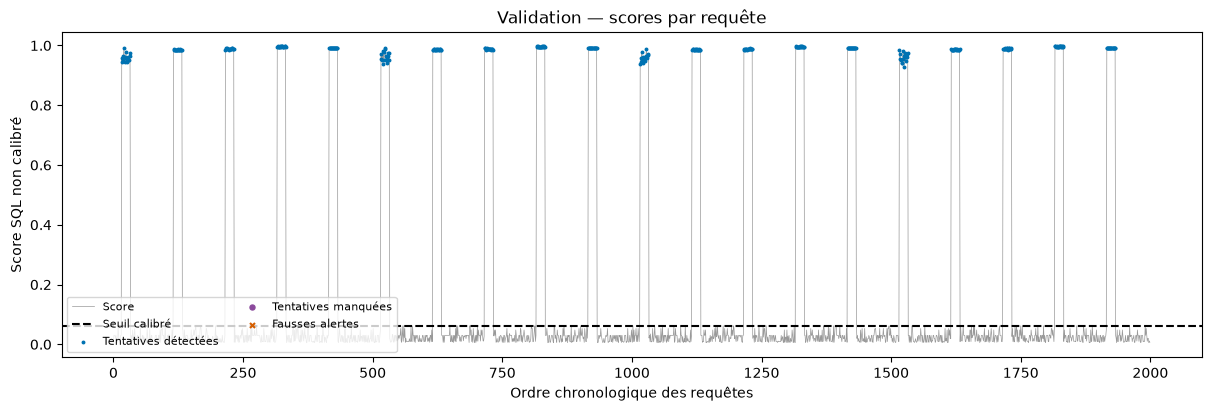

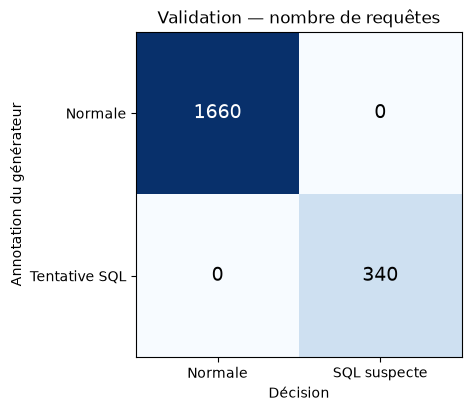

In [3]:
df = predictions["validation"].sort_values("observed_at").reset_index(drop=True)
y, p = df.is_attack.eq(1), df.predicted_sql.eq(1)
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
ax.plot(df.index, df.sql_score, color="#999999", lw=.5, label="Score")
ax.axhline(threshold, color="black", ls="--", label="Seuil calibré")
for mask, label, color, marker in [(y & p, "Tentatives détectées", "#0072B2", "."),
                                    (y & ~p, "Tentatives manquées", "#8B4A9C", "o"),
                                    (~y & p, "Fausses alertes", "#D55E00", "x")]:
    ax.scatter(df.index[mask], df.loc[mask, "sql_score"], label=label, color=color, marker=marker, s=13, zorder=3)
ax.set(title="Validation — scores par requête", xlabel="Ordre chronologique des requêtes", ylabel="Score SQL non calibré")
ax.legend(loc="lower left", fontsize=8, ncol=2)
plt.show()

s = summary.loc["validation"]
cm = np.array([[s.VN, s.FP], [s.FN, s.VP]], dtype=int)
fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
ax.imshow(cm, cmap="Blues")
for (i,j),value in np.ndenumerate(cm):
    ax.text(j,i,str(value),ha="center",va="center",fontsize=14,
            color="white" if value > cm.max()/2 else "black")
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=["Normale", "SQL suspecte"],
       yticklabels=["Normale", "Tentative SQL"],xlabel="Décision",ylabel="Annotation du générateur",
       title="Validation — nombre de requêtes")
plt.show()


## 3. Scénarios et épisodes

Un épisode est une session synthétique contenant des tentatives. Il est « détecté » si au moins une tentative est signalée. Le délai est calculé entre la première tentative de la session et la première tentative détectée ; ce n'est pas un délai de collecte Loki ou d'exécution en direct.


In [4]:
v = report["splits"]["validation"]
display(pd.DataFrame(v["by_scenario"]))
episodes = pd.DataFrame(v["episodes"])
print(f"Épisodes repérés : {int(episodes.detected.sum())}/{len(episodes)}")
print("Sessions entièrement normales ayant au moins une alerte :", v["normal_sessions_with_alert"])
display(episodes)


,scenario,attack_requests,detected_requests,recall
0,boolean,68,68,1.0
1,comment,68,68,1.0
2,metadata,68,68,1.0
3,time,68,68,1.0
4,union,68,68,1.0


Épisodes repérés : 20/20
Sessions entièrement normales ayant au moins une alerte : 0


,session_id,scenario,attack_requests,detected_requests,detected,delay_seconds_observed
0,validation-0000,boolean,17,17,True,0.0
1,validation-0002,union,17,17,True,0.0
2,validation-0004,comment,17,17,True,0.0
3,validation-0006,time,17,17,True,0.0
4,validation-0008,metadata,17,17,True,0.0
5,validation-0010,boolean,17,17,True,0.0
6,validation-0012,union,17,17,True,0.0
7,validation-0014,comment,17,17,True,0.0
8,validation-0016,time,17,17,True,0.0
9,validation-0018,metadata,17,17,True,0.0


## 4. Examiner les tentatives manquées et les fausses alertes

Le décodage ci-dessous sert uniquement à lire les exemples. Les apostrophes, les espaces et l'encodage existent aussi dans les requêtes normales : ils ne suffisent pas seuls à affirmer une attaque.


In [5]:
columns = ["observed_at", "session_id", "scenario", "query", "sql_score"]
missed = df[y & ~p].copy()
false_alerts = df[~y & p].copy()
print("Tentatives manquées :", len(missed))
examples = missed.head(12)[columns].copy()
examples["query_decoded_for_reading"] = examples["query"].map(lambda value: unquote_plus(unquote_plus(value)))
display(examples)
print("Fausses alertes :", len(false_alerts))
display(false_alerts.head(12)[columns])


Tentatives manquées : 0


,observed_at,session_id,scenario,query,sql_score,query_decoded_for_reading


Fausses alertes : 0


,observed_at,session_id,scenario,query,sql_score


## Séquences effectivement apprises
Poids positifs : favorisent la classe SQL ; poids négatifs : favorisent la classe normale. Leur effet dépend de la représentation TF-IDF complète, pas d’une règle indépendante par séquence.


In [6]:
weights = pd.read_csv(EXP_DIR / "learned_ngrams.csv", keep_default_na=False)
display(weights.nlargest(12, "weight_sql"))
display(weights.nsmallest(12, "weight_sql"))


,ngram,weight_sql
0,',6.410960
1,-,4.582437
2,--,4.582437
3,--,4.582437
4,' o,3.553079
5,' or,3.553079
6,' or,3.553079
7,d',2.843754
8,d',2.843754
9,ed',2.843754


,ngram,weight_sql
30,q=,-0.942572
31,tion,-0.804759
32,ent,-0.696832
33,nt,-0.696832
34,=c,-0.674266
35,q=c,-0.661058
36,de,-0.653314
37,=co,-0.611978
38,=com,-0.611978
39,=comm,-0.611978


## Limites et suite

Les familles SQL sont connues dès l'entraînement. Les gabarits SQL, les requêtes SQL normalisées et les sessions sont séparés entre les quatre périodes ; des variantes peuvent néanmoins rester très proches. Le générateur est connu et le vocabulaire normal reste limité. Un résultat parfait sur cette validation ne garantit pas un résultat parfait sur un scénario réel.

L'URL est la seule entrée : ni l'IP, ni la route, ni le statut, ni les annotations ne constituent des variables du modèle. Les corps POST ne sont pas observables. Une tentative détectée ne prouve pas qu'elle a réussi ; une requête inconnue peut être mal classée.

Le test reste réservé. Le prochain contrôle utile est le scénario réel UNION SELECT de l'équipe, avec des requêtes normales réelles incluant ponctuation et mots proches du SQL. Les alertes SIEM ne déclenchent pas à la place du ML la décision de blocage de la démonstration.

L'artefact de scoring peut produire un fichier local de détections. Le contrat d'alerte officiel et le moteur de remédiation sont à raccorder séparément. Une résolution nécessite une vérification, et bloquer une IP n'annule pas une éventuelle divulgation antérieure.
